# Anemia Dataset: EDA and Model Comparison

This first-pass study explores a small Kaggle dataset labeled for anemia and compares Logistic Regression with XGBoost. It is a portfolio exercise, not a clinical model. The dataset is about anemia, not specifically iron deficiency.

> **Important limitation:** the label may be determined directly from hemoglobin or other CBC measurements that are also provided as predictors. This creates a serious risk of target leakage. Even strong held-out metrics would not establish useful prediction of future anemia or iron deficiency, clinical validity, or generalizability. Review provenance and label construction before interpreting results.

## Data source and download

Source: [Anemia Dataset on Kaggle](https://www.kaggle.com/datasets/biswaranjanrao/anemia-dataset). The Kaggle page describes `Gender` as 0 = male and 1 = female, and `Result` as 0 = not anemic and 1 = anemic. Its license metadata is unknown; review the source terms before redistribution or commercial use.

The provided `data/anemia.csv` is already present, so the download can be skipped. To download it yourself, install the Kaggle CLI, configure Kaggle API credentials according to Kaggle's documentation (never put tokens in this notebook or repository), then run from the repository root:

```bash
python -m pip install kaggle
kaggle datasets download -d biswaranjanrao/anemia-dataset -p data --unzip
```

Alternatively, download the dataset ZIP from the Kaggle page into `data/`; the loader below can read the CSV from that archive.

In [1]:
from pathlib import Path
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

RANDOM_STATE = 42
DATA_DIR = Path('../data') if Path('../data').exists() else Path('data')
CSV_PATH = DATA_DIR / 'anemia.csv'
ZIP_PATH = DATA_DIR / 'anemia.zip'
TARGET = 'Result'
FEATURES = ['Gender', 'Hemoglobin', 'MCH', 'MCHC', 'MCV']

## Load and validate

The loader accepts either the extracted CSV or an optional `anemia.zip`. It fails clearly if neither is found. The numeric encodings below follow the Kaggle page and should be rechecked against the original source before reuse.

In [2]:
if CSV_PATH.is_file():
    df = pd.read_csv(CSV_PATH)
elif ZIP_PATH.is_file():
    with zipfile.ZipFile(ZIP_PATH) as archive:
        csv_names = [name for name in archive.namelist() if name.lower().endswith('.csv')]
        if not csv_names:
            raise FileNotFoundError(f'No CSV found inside {ZIP_PATH}')
        preferred = next((name for name in csv_names if Path(name).name.lower() == 'anemia.csv'), csv_names[0])
        with archive.open(preferred) as csv_file:
            df = pd.read_csv(csv_file)
else:
    raise FileNotFoundError(
        f'Dataset not found. Put anemia.csv or anemia.zip in {DATA_DIR.resolve()}.'
    )

# Treat whitespace-only cells as missing before inspecting or modeling.
df = df.replace(r'^\s*$', np.nan, regex=True)
expected_columns = FEATURES + [TARGET]
missing_columns = sorted(set(expected_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f'Missing expected columns: {missing_columns}')

df = df[expected_columns].copy()
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
display(df.head())
display(df.dtypes.to_frame('dtype'))

Shape: 1,421 rows x 6 columns


,Gender,Hemoglobin,MCH,MCHC,MCV,Result
0,1,14.9,22.7,29.1,83.7,0
1,0,15.9,25.4,28.3,72.0,0
2,0,9.0,21.5,29.6,71.2,1
3,0,14.9,16.0,31.4,87.5,0
4,1,14.7,22.0,28.2,99.5,0


,dtype
Gender,int64
Hemoglobin,float64
MCH,float64
MCHC,float64
MCV,float64
Result,int64


## Data quality and exploratory analysis

Check missingness, duplicates, class balance, ranges, and feature distributions before fitting models. This file contains many exact duplicate rows and no participant identifiers to distinguish repeated records. The notebook reports and removes exact duplicates before splitting to prevent identical rows from appearing in both training and test partitions; this reduces the analysis set from 1,421 rows to 534 unique rows. Treat this as a conservative modeling choice, and verify the dataset's provenance and record semantics.

In [3]:
# Convert expected numeric fields explicitly; unexpected text becomes missing and is surfaced below.
for column in expected_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

print('Missing values by column:')
display(df.isna().sum().rename('missing_count').to_frame())
print('Descriptive statistics before duplicate removal:')
display(df.describe().T)

duplicate_count = int(df.duplicated().sum())
print(f'Exact duplicate rows: {duplicate_count:,} of {len(df):,}')
# Identical rows cannot be distinguished across splits without participant IDs.
df = df.drop_duplicates().reset_index(drop=True)
print(f'Rows retained for analysis after exact deduplication: {len(df):,}')

if df[TARGET].isna().any():
    raise ValueError('Target contains missing or non-numeric values; resolve before splitting.')
if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError(f'Expected binary Result labels 0/1, got {sorted(df[TARGET].unique())}')
if df[FEATURES].isna().all(axis=None):
    raise ValueError('All feature values are missing after numeric conversion.')

class_counts = df[TARGET].value_counts().sort_index()
class_summary = pd.DataFrame({
    'count': class_counts,
    'proportion': df[TARGET].value_counts(normalize=True).sort_index(),
})
class_summary.index = class_summary.index.map({0: 'Not anemic (0)', 1: 'Anemic (1)'})
display(class_summary)

Missing values by column:


,missing_count
Gender,0
Hemoglobin,0
MCH,0
MCHC,0
MCV,0
Result,0


Descriptive statistics before duplicate removal:


,count,mean,std,min,25%,50%,75%,max
Gender,1421.0,0.520760,0.499745,0.0,0.0,1.0,1.0,1.0
Hemoglobin,1421.0,13.412738,1.974546,6.6,11.7,13.2,15.0,16.9
MCH,1421.0,22.905630,3.969375,16.0,19.4,22.7,26.2,30.0
MCHC,1421.0,30.251232,1.400898,27.8,29.0,30.4,31.4,32.5
MCV,1421.0,85.523786,9.636701,69.4,77.3,85.3,94.2,101.6
Result,1421.0,0.436312,0.496102,0.0,0.0,0.0,1.0,1.0


Exact duplicate rows: 887 of 1,421
Rows retained for analysis after exact deduplication: 534


,count,proportion
Result,,
Not anemic (0),287,0.537453
Anemic (1),247,0.462547


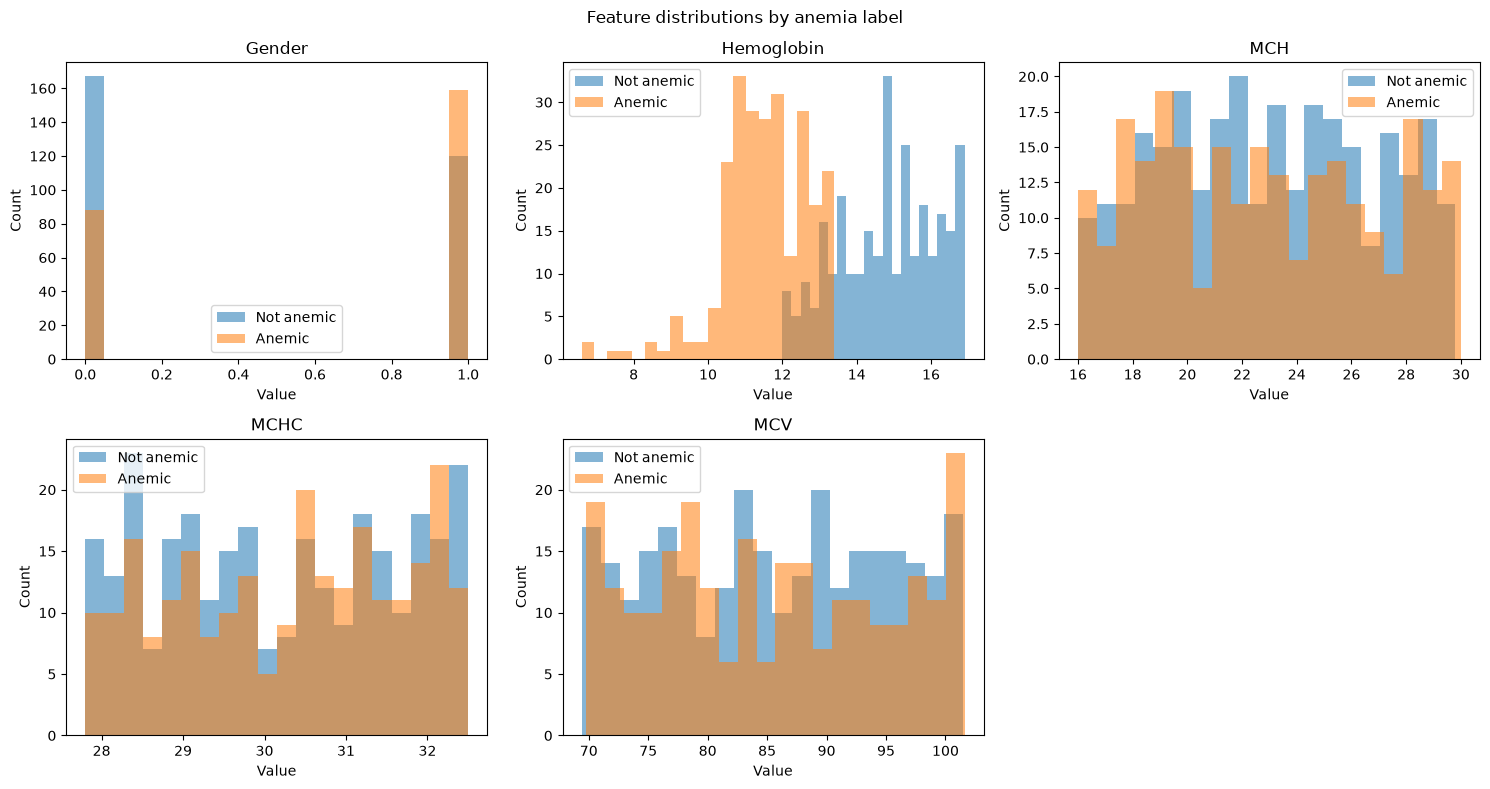

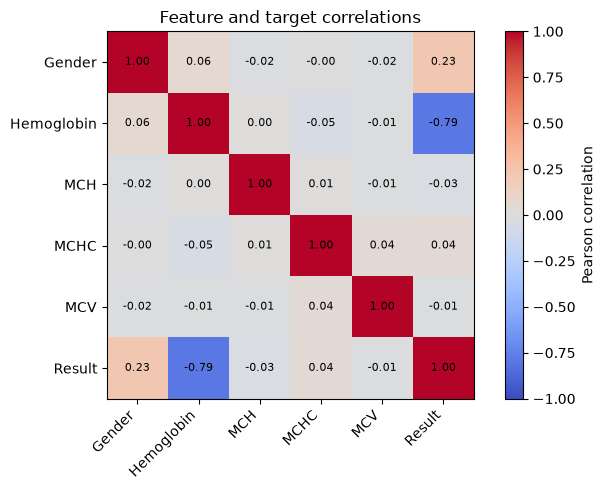

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature in zip(axes.flat, FEATURES):
    for label, name in [(0, 'Not anemic'), (1, 'Anemic')]:
        values = df.loc[df[TARGET] == label, feature].dropna()
        ax.hist(values, bins=20, alpha=0.55, label=name)
    ax.set_title(feature)
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')
    ax.legend()
axes.flat[-1].axis('off')
fig.suptitle('Feature distributions by anemia label')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
correlation = df[FEATURES + [TARGET]].corr(numeric_only=True)
image = ax.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha='right')
ax.set_yticks(range(len(correlation.index)), correlation.index)
for row in range(len(correlation.index)):
    for column in range(len(correlation.columns)):
        ax.text(column, row, f'{correlation.iloc[row, column]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, label='Pearson correlation')
ax.set_title('Feature and target correlations')
fig.tight_layout()
plt.show()

## Stratified train / validation / test split

Reserve 20% for final testing. Split the remaining 80% into 60% training and 20% validation. Feature ranking and model/feature-count selection use training and validation only; the test partition is kept untouched until final evaluation.

In [5]:
X = df[FEATURES].copy()
y = df[TARGET].astype(int)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=RANDOM_STATE
)

for name, target in [('train', y_train), ('validation', y_validation), ('test', y_test)]:
    print(f'{name:10s}: n={len(target):4d}, positive rate={target.mean():.3f}')

mi_scores = mutual_info_classif(
    X_train.fillna(X_train.median()), y_train, random_state=RANDOM_STATE
)
feature_ranking = pd.Series(mi_scores, index=FEATURES, name='mutual_information').sort_values(ascending=False)
print('Feature ranking fitted on the training partition only:')
display(feature_ranking.to_frame())

train     : n= 320, positive rate=0.463
validation: n= 107, positive rate=0.467
test      : n= 107, positive rate=0.458
Feature ranking fitted on the training partition only:


,mutual_information
Hemoglobin,0.506827
MCV,0.051373
MCHC,0.018354
Gender,0.011583
MCH,0.000000


## Model selection on validation AUPRC

Mutual-information ranking is computed from training data only. For each model, choose among the top 3, 4, or 5 ranked features using validation average precision (AUPRC). The validation metric guides selection; it is not the final reported performance. The final model is refit on train + validation and evaluated once on test.

In [6]:
def build_model(model_name):
    if model_name == 'Logistic Regression':
        return make_pipeline(
            SimpleImputer(strategy='median'),
            StandardScaler(),
            LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
        )
    if model_name == 'XGBoost':
        return make_pipeline(
            SimpleImputer(strategy='median'),
            XGBClassifier(
                n_estimators=200,
                max_depth=3,
                learning_rate=0.05,
                subsample=0.9,
                colsample_bytree=0.9,
                eval_metric='logloss',
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        )
    raise ValueError(f'Unknown model: {model_name}')

model_names = ['Logistic Regression', 'XGBoost']
candidate_rows = []
best_k = {}

for model_name in model_names:
    candidates = []
    for k in [3, 4, 5]:
        selected_features = feature_ranking.head(k).index.tolist()
        candidate_model = build_model(model_name)
        candidate_model.fit(X_train[selected_features], y_train)
        validation_probability = candidate_model.predict_proba(X_validation[selected_features])[:, 1]
        validation_auprc = average_precision_score(y_validation, validation_probability)
        candidates.append((validation_auprc, k, selected_features))
        candidate_rows.append({
            'model': model_name, 'k': k, 'features': ', '.join(selected_features),
            'validation_auprc': validation_auprc,
        })
    best_auprc, chosen_k, chosen_features = max(candidates, key=lambda item: (item[0], -item[1]))
    best_k[model_name] = chosen_k
    print(f'{model_name}: selected k={chosen_k}, validation AUPRC={best_auprc:.3f}; features={chosen_features}')

validation_results = pd.DataFrame(candidate_rows).sort_values(['model', 'k'])
display(validation_results)

Logistic Regression: selected k=4, validation AUPRC=1.000; features=['Hemoglobin', 'MCV', 'MCHC', 'Gender']
XGBoost: selected k=4, validation AUPRC=1.000; features=['Hemoglobin', 'MCV', 'MCHC', 'Gender']


,model,k,features,validation_auprc
0,Logistic Regression,3,"Hemoglobin, MCV, MCHC",0.975362
1,Logistic Regression,4,"Hemoglobin, MCV, MCHC, Gender",1.000000
2,Logistic Regression,5,"Hemoglobin, MCV, MCHC, Gender, MCH",0.998446
3,XGBoost,3,"Hemoglobin, MCV, MCHC",0.973577
4,XGBoost,4,"Hemoglobin, MCV, MCHC, Gender",1.000000
5,XGBoost,5,"Hemoglobin, MCV, MCHC, Gender, MCH",1.000000


## Final held-out test comparison

AUPRC is reported as average precision, the area-under-precision-recall summary commonly used by scikit-learn. Accuracy uses the default 0.5 probability threshold. Balanced accuracy is included to account for class proportions. No threshold tuning is performed on the test set.

In [7]:
X_final_train = pd.concat([X_train, X_validation])
y_final_train = pd.concat([y_train, y_validation])
test_models = {}
test_probabilities = {}
test_predictions = {}
result_rows = []

for model_name in model_names:
    selected_features = feature_ranking.head(best_k[model_name]).index.tolist()
    final_model = build_model(model_name)
    final_model.fit(X_final_train[selected_features], y_final_train)
    probability = final_model.predict_proba(X_test[selected_features])[:, 1]
    prediction = (probability >= 0.5).astype(int)
    test_models[model_name] = final_model
    test_probabilities[model_name] = probability
    test_predictions[model_name] = prediction
    result_rows.append({
        'model': model_name,
        'selected_k': best_k[model_name],
        'accuracy': accuracy_score(y_test, prediction),
        'balanced_accuracy': balanced_accuracy_score(y_test, prediction),
        'roc_auc': roc_auc_score(y_test, probability),
        'auprc': average_precision_score(y_test, probability),
    })

comparison = pd.DataFrame(result_rows).set_index('model').sort_values('auprc', ascending=False)
display(comparison.style.format('{:.3f}'))

,selected_k,accuracy,balanced_accuracy,roc_auc,auprc
model,,,,,
Logistic Regression,4.000,0.981,0.983,1.000,1.000
XGBoost,4.000,1.000,1.000,1.000,1.000


In [9]:
import joblib

xgb_features = feature_ranking.head(best_k['XGBoost']).index.tolist()
model_path = DATA_DIR.parent / 'models' / 'anemia_xgb_pipeline.joblib'
model_path.parent.mkdir(parents=True, exist_ok=True)

model_artifact = {
    'model': test_models['XGBoost'],
    'features': xgb_features,
    'target': TARGET,
    'positive_class': 1,
    'class_labels': {0: 'Not anemic', 1: 'Anemic'},
    'test_metrics': comparison.loc['XGBoost'].to_dict(),
    'dataset': 'biswaranjanrao/anemia-dataset',
    'random_state': RANDOM_STATE,
}
joblib.dump(model_artifact, model_path)
print(f'Saved XGBoost pipeline and metadata to {model_path}')
print(f'Model input features: {xgb_features}')

Saved XGBoost pipeline and metadata to ../models/anemia_xgb_pipeline.joblib
Model input features: ['Hemoglobin', 'MCV', 'MCHC', 'Gender']


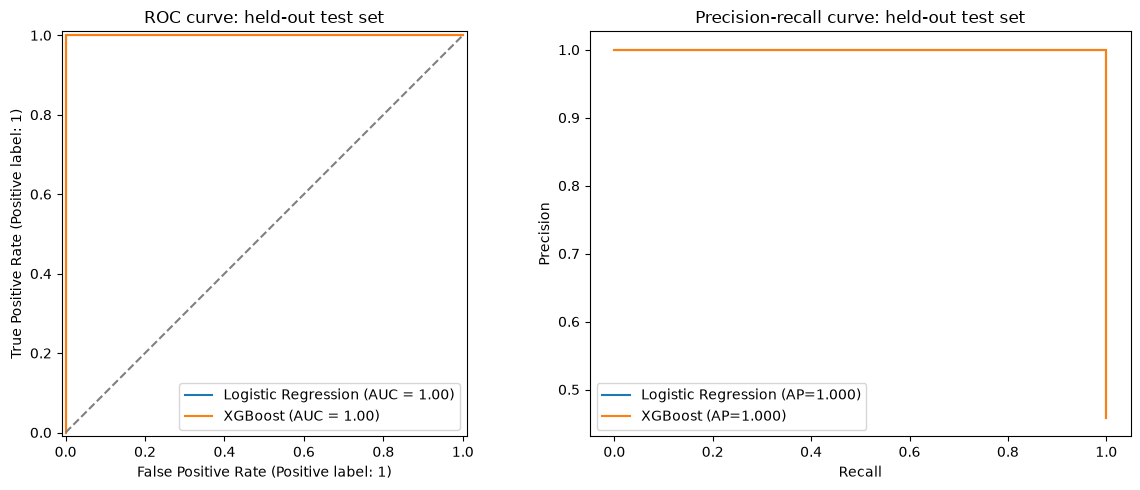


Logistic Regression | selected features: ['Hemoglobin', 'MCV', 'MCHC', 'Gender']
              precision    recall  f1-score   support

  Not anemic       1.00      0.97      0.98        58
      Anemic       0.96      1.00      0.98        49

    accuracy                           0.98       107
   macro avg       0.98      0.98      0.98       107
weighted avg       0.98      0.98      0.98       107



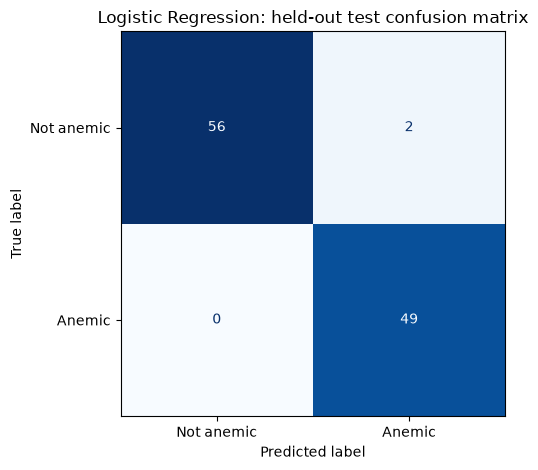


XGBoost | selected features: ['Hemoglobin', 'MCV', 'MCHC', 'Gender']
              precision    recall  f1-score   support

  Not anemic       1.00      1.00      1.00        58
      Anemic       1.00      1.00      1.00        49

    accuracy                           1.00       107
   macro avg       1.00      1.00      1.00       107
weighted avg       1.00      1.00      1.00       107



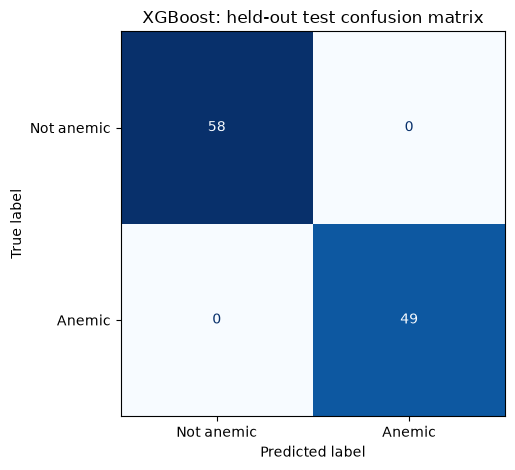

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for model_name, probability in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, probability, name=model_name, ax=axes[0])
    precision, recall, _ = precision_recall_curve(y_test, probability)
    axes[1].plot(recall, precision, label=f'{model_name} (AP={average_precision_score(y_test, probability):.3f})')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
axes[0].set_title('ROC curve: held-out test set')
axes[1].set_title('Precision-recall curve: held-out test set')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()
fig.tight_layout()
plt.show()

for model_name, prediction in test_predictions.items():
    print(f'\n{model_name} | selected features: {feature_ranking.head(best_k[model_name]).index.tolist()}')
    print(classification_report(y_test, prediction, target_names=['Not anemic', 'Anemic'], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, display_labels=['Not anemic', 'Anemic'], cmap='Blues', colorbar=False
    )
    plt.title(f'{model_name}: held-out test confusion matrix')
    plt.tight_layout()
    plt.show()

## Interpretation and next steps

Use the tables and plots above to compare the two models on this one split. Do not interpret a higher score as evidence that the model predicts future disease: the target construction and data provenance are not established here, and CBC features may be the same measurements used to define the anemia label. The dataset is small, its representativeness is unclear, and the Kaggle listing reports unknown license metadata.

Before extending this work, verify how `Result` was created, establish dataset provenance and permitted use, assess duplicates and possible synthetic or repeated records, and use an external cohort with a clinically meaningful prediction time point. This dataset does not establish iron deficiency and must not inform diagnosis or treatment.